<a href="https://colab.research.google.com/github/mohamedmorsy-ai/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohamedmorsy-ai/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

In [3]:
from IPython.display import display, Markdown

display(Markdown("""
### Research Question

Can historical organic search performance predict whether
a content item will lose more than 20% of its search impressions
during the following 30 days?

### Business Problem

Content teams manage many pages with limited time and resources.
Reviewing every page manually is inefficient.

### Decision Supported

The research supports a ranked content-review queue.
High-risk pages can be investigated before lower-risk pages.

### Research Objectives

1. Analyze historical search performance.
2. Engineer predictive features using DuckDB.
3. Define a future impression-decline label.
4. Train a Random Forest classifier.
5. Compare against simple baselines.
6. Validate predictions on unseen clients.
7. Generate ranked content-review recommendations.

### Hypothesis

Historical impressions, clicks, search positions, and
performance momentum contain information associated
with future search visibility decline.

This is an observational prediction study.
It does not aim to explain Google's ranking algorithm.
"""))

print("Section 1 completed.")


### Research Question

Can historical organic search performance predict whether
a content item will lose more than 20% of its search impressions
during the following 30 days?

### Business Problem

Content teams manage many pages with limited time and resources.
Reviewing every page manually is inefficient.

### Decision Supported

The research supports a ranked content-review queue.
High-risk pages can be investigated before lower-risk pages.

### Research Objectives

1. Analyze historical search performance.
2. Engineer predictive features using DuckDB.
3. Define a future impression-decline label.
4. Train a Random Forest classifier.
5. Compare against simple baselines.
6. Validate predictions on unseen clients.
7. Generate ranked content-review recommendations.

### Hypothesis

Historical impressions, clicks, search positions, and
performance momentum contain information associated
with future search visibility decline.

This is an observational prediction study.
It does not aim to explain Google's ranking algorithm.


Section 1 completed.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [4]:

%pip -q install duckdb huggingface_hub pandas numpy scikit-learn matplotlib pyarrow

import os
import re
import duckdb
import numpy as np
import pandas as pd

from pathlib import Path
from getpass import getpass
from IPython.display import display, Markdown

# ==========================================
# 1. Project Configuration
# ==========================================

SEED = 42

OUTDIR = Path("/content/capstone_outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

PRIVATE = Path("/content/_flyrank_private")
PRIVATE.mkdir(parents=True, exist_ok=True)

print("FlyRank Capstone - Data Preparation")
print("Libraries loaded successfully.")

# ==========================================
# 2. Hugging Face Authentication
# ==========================================

HF_TOKEN = getpass(
    "Paste your Hugging Face READ token (hf_...): "
).strip()

if not re.fullmatch(r"hf_[A-Za-z0-9_]+", HF_TOKEN):
    raise ValueError(
        "Invalid token format. A Hugging Face token starts with hf_."
    )

con = duckdb.connect()

con.execute(
    f"CREATE OR REPLACE SECRET hf "
    f"(TYPE huggingface, TOKEN '{HF_TOKEN}')"
)

del HF_TOKEN

print("Authentication configured successfully.")

# ==========================================
# 3. Dataset Connection
# ==========================================

REL = "hf://datasets/FlyRank/internship-warehouse"

CLIENTS = f"read_parquet('{REL}/dim_clients.parquet')"

months = [
    "2026-03",
    "2026-04",
    "2026-05"
]

paths = [
    f"'{REL}/fact_content_daily_performance/"
    f"month={m}/*.parquet'"
    for m in months
]

FACT = "read_parquet([" + ", ".join(paths) + "])"

CACHE = PRIVATE / "capstone_features.parquet"

print("Dataset configured.")
print("Selected months:", months)

# ==========================================
# 4. Feature Extraction Using DuckDB
# ==========================================

if CACHE.exists():

    data = pd.read_parquet(CACHE)
    print("Loaded cached feature table.")

else:

    print("Connecting to FlyRank warehouse...")
    print("Aggregating historical performance data...")

    query = f"""
    WITH daily AS (
        SELECT
            f.client_hash_id,
            f.content_hash_id,

            SUM(CASE WHEN f.report_date BETWEEN
                DATE '2026-03-03' AND DATE '2026-04-01'
                THEN COALESCE(f.gsc_impressions, 0)
                ELSE 0 END) AS imp1,

            SUM(CASE WHEN f.report_date BETWEEN
                DATE '2026-04-02' AND DATE '2026-05-01'
                THEN COALESCE(f.gsc_impressions, 0)
                ELSE 0 END) AS imp2,

            SUM(CASE WHEN f.report_date BETWEEN
                DATE '2026-05-02' AND DATE '2026-05-31'
                THEN COALESCE(f.gsc_impressions, 0)
                ELSE 0 END) AS imp3,

            SUM(CASE WHEN f.report_date BETWEEN
                DATE '2026-03-03' AND DATE '2026-04-01'
                THEN COALESCE(f.gsc_clicks, 0)
                ELSE 0 END) AS clicks1,

            SUM(CASE WHEN f.report_date BETWEEN
                DATE '2026-04-02' AND DATE '2026-05-01'
                THEN COALESCE(f.gsc_clicks, 0)
                ELSE 0 END) AS clicks2,

            AVG(CASE WHEN f.report_date BETWEEN
                DATE '2026-03-03' AND DATE '2026-04-01'
                AND f.gsc_avg_position > 0
                THEN f.gsc_avg_position END) AS pos1,

            AVG(CASE WHEN f.report_date BETWEEN
                DATE '2026-04-02' AND DATE '2026-05-01'
                AND f.gsc_avg_position > 0
                THEN f.gsc_avg_position END) AS pos2,

            COUNT(DISTINCT CASE WHEN f.report_date BETWEEN
                DATE '2026-03-03' AND DATE '2026-04-01'
                THEN f.report_date END) AS days1,

            COUNT(DISTINCT CASE WHEN f.report_date BETWEEN
                DATE '2026-04-02' AND DATE '2026-05-01'
                THEN f.report_date END) AS days2,

            COUNT(DISTINCT CASE WHEN f.report_date BETWEEN
                DATE '2026-05-02' AND DATE '2026-05-31'
                THEN f.report_date END) AS days3

        FROM {FACT} AS f

        INNER JOIN {CLIENTS} AS c
            ON f.client_hash_id = c.client_hash_id

        WHERE f.report_date BETWEEN
            DATE '2026-03-03' AND DATE '2026-05-31'

        AND c.gsc_data_start <= DATE '2026-03-03'

        GROUP BY 1, 2
    )

    SELECT *
    FROM daily

    WHERE imp1 >= 100
      AND imp2 >= 100
      AND days1 >= 5
      AND days2 >= 5
      AND days3 >= 5
    """

    data = con.sql(query).df()

    data.to_parquet(CACHE, index=False)

    print("Feature extraction completed.")

# ==========================================
# 5. Validate Extracted Data
# ==========================================

if data.empty:
    raise ValueError(
        "No eligible observations found. "
        "Check the dataset and observation windows."
    )

# ==========================================
# 6. Feature Engineering
# ==========================================

data["ctr1"] = (
    data["clicks1"] / data["imp1"]
)

data["ctr2"] = (
    data["clicks2"] / data["imp2"]
)

data["momentum"] = (
    data["imp2"] - data["imp1"]
) / data["imp1"]

data["position_change"] = (
    data["pos2"] - data["pos1"]
)

# Future impression decline > 20%
data["decline"] = (
    data["imp3"] < 0.80 * data["imp2"]
).astype(int)

# ==========================================
# 7. Dataset Description
# ==========================================

display(Markdown("""
## 2. Data

### Data Source

This research uses the FlyRank Internship Warehouse
hosted on Hugging Face.

The full published release contains approximately
78.8 million daily organic search performance records.

### Tables

- `dim_clients`: Pseudonymized client information.
- `fact_content_daily_performance`: Daily search metrics.

### Historical Observation Windows

- March 3 – April 1, 2026.
- April 2 – May 1, 2026.

### Future Prediction Window

- May 2 – May 31, 2026.

### Data Filtering

Content items must have:

- At least 100 impressions in each historical window.
- At least five observed days in each historical window.
- At least five observed days in the future period.

The future-coverage filter may exclude content items
that completely disappear from reporting. This is
a selection limitation of the experiment.

### Feature Engineering

Historical variables include:

1. Search impressions.
2. Search clicks.
3. Click-through rates.
4. Average search positions.
5. Impression momentum.
6. Position change.

### Target Definition

The target variable identifies content with
a future impression decline exceeding 20%.

### Privacy

No private client names, raw search queries,
website URLs, or authentication tokens are
included in published research results.

### Processing Method

DuckDB processes remote Parquet files using SQL.
Only aggregated results are transferred to Pandas.
"""))

# ==========================================
# 8. Dataset Summary
# ==========================================

print("=" * 50)
print("FLYRANK CAPSTONE - DATA SUMMARY")
print("=" * 50)

print("Eligible observations:", f"{len(data):,}")

print(
    "Unique clients:",
    data["client_hash_id"].nunique()
)

print(
    "Observed decline rate:",
    f"{data['decline'].mean():.2%}"
)

print(
    "Number of columns:",
    len(data.columns)
)

print("\nFeature sample:")
display(
    data[
        [
            "imp1",
            "imp2",
            "imp3",
            "ctr1",
            "ctr2",
            "momentum",
            "decline"
        ]
    ].head()
)

print("\nSection 2 completed successfully.")


FlyRank Capstone - Data Preparation
Libraries loaded successfully.
Paste your Hugging Face READ token (hf_...): ··········
Authentication configured successfully.
Dataset configured.
Selected months: ['2026-03', '2026-04', '2026-05']
Connecting to FlyRank warehouse...
Aggregating historical performance data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Feature extraction completed.



## 2. Data

### Data Source

This research uses the FlyRank Internship Warehouse
hosted on Hugging Face.

The full published release contains approximately
78.8 million daily organic search performance records.

### Tables

- `dim_clients`: Pseudonymized client information.
- `fact_content_daily_performance`: Daily search metrics.

### Historical Observation Windows

- March 3 – April 1, 2026.
- April 2 – May 1, 2026.

### Future Prediction Window

- May 2 – May 31, 2026.

### Data Filtering

Content items must have:

- At least 100 impressions in each historical window.
- At least five observed days in each historical window.
- At least five observed days in the future period.

The future-coverage filter may exclude content items
that completely disappear from reporting. This is
a selection limitation of the experiment.

### Feature Engineering

Historical variables include:

1. Search impressions.
2. Search clicks.
3. Click-through rates.
4. Average search positions.
5. Impression momentum.
6. Position change.

### Target Definition

The target variable identifies content with
a future impression decline exceeding 20%.

### Privacy

No private client names, raw search queries,
website URLs, or authentication tokens are
included in published research results.

### Processing Method

DuckDB processes remote Parquet files using SQL.
Only aggregated results are transferred to Pandas.


FLYRANK CAPSTONE - DATA SUMMARY
Eligible observations: 88,272
Unique clients: 38
Observed decline rate: 57.87%
Number of columns: 17

Feature sample:


,imp1,imp2,imp3,ctr1,ctr2,momentum,decline
0,482.0,462.0,33.0,0.002075,0.000000,-0.041494,1
1,563.0,228.0,176.0,0.010657,0.008772,-0.595027,1
2,388.0,307.0,325.0,0.002577,0.000000,-0.208763,0
3,357.0,250.0,262.0,0.000000,0.000000,-0.299720,0
4,2179.0,895.0,781.0,0.003212,0.007821,-0.589261,0



Section 2 completed successfully.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

In [5]:
%pip -q install -U duckdb huggingface_hub pandas numpy scikit-learn matplotlib pyarrow

import os
import re
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

print("Libraries imported successfully.")
print("DuckDB version:", duckdb.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.
Libraries imported successfully.
DuckDB version: 1.3.2


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [7]:

# ==========================================
# FLYRANK CAPSTONE - CELL 4
# Results vs Baseline
# ==========================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display, Markdown

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# 1. Check Data
# ==========================================

if "data" not in globals():
    raise RuntimeError(
        "Run Cell 2 first to load the FlyRank dataset."
    )

SEED = 42

OUTDIR = Path("/content/capstone_outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

feature_cols = [
    "imp1",
    "imp2",
    "clicks1",
    "clicks2",
    "ctr1",
    "ctr2",
    "pos1",
    "pos2",
    "momentum",
    "position_change",
    "days1",
    "days2"
]

X = data[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

y = data["decline"]
groups = data["client_hash_id"]

if groups.nunique() < 4:
    raise ValueError(
        "Not enough clients for grouped validation."
    )

# ==========================================
# 2. Split Data by Client
# ==========================================

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=SEED
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_clients = set(groups.iloc[train_idx])
test_clients = set(groups.iloc[test_idx])

assert train_clients.isdisjoint(test_clients)

if y_train.nunique() != 2:
    raise ValueError(
        "Training data must contain both classes."
    )

print("Data split successfully.")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training clients:", len(train_clients))
print("Testing clients:", len(test_clients))

# ==========================================
# 3. Train Random Forest
# ==========================================

model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )),
    ("forest", RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

rf_pred = model.predict(X_test)
rf_score = model.predict_proba(X_test)[:, 1]

print("\nRandom Forest training completed.")

# ==========================================
# 4. Majority Baseline
# ==========================================

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

base_pred = baseline.predict(X_test)

print("Majority baseline completed.")

# ==========================================
# 5. Historical Momentum Baseline
# ==========================================

rule_pred = (
    X_test["momentum"] < -0.20
).astype(int).to_numpy()

print("Historical momentum baseline completed.")

# ==========================================
# 6. Evaluation Function
# ==========================================

def evaluate(name, predicted):
    return {
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, predicted
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predicted
        ),

        "Precision": precision_score(
            y_test, predicted, zero_division=0
        ),

        "Recall": recall_score(
            y_test, predicted, zero_division=0
        ),

        "F1": f1_score(
            y_test, predicted, zero_division=0
        )
    }

# ==========================================
# 7. Compare Models
# ==========================================

results = pd.DataFrame([
    evaluate("Majority baseline", base_pred),
    evaluate("Momentum rule", rule_pred),
    evaluate("Random Forest", rf_pred)
])

display(Markdown("## Model Performance Comparison"))

display(results.round(3))

# ==========================================
# 8. Calculate Metrics
# ==========================================

rf_acc = accuracy_score(y_test, rf_pred)
base_acc = accuracy_score(y_test, base_pred)

delta = rf_acc - base_acc

base_rate = float(y_test.mean())

if y_test.nunique() == 2:
    auc = roc_auc_score(y_test, rf_score)
    ap = average_precision_score(y_test, rf_score)
else:
    auc = np.nan
    ap = np.nan

def precision_at_k(scores, labels, k):
    scores = np.asarray(scores)
    labels = np.asarray(labels)

    order = np.argsort(-scores, kind="stable")
    selected = order[:min(k, len(labels))]

    return float(labels[selected].mean())

K = min(20, len(y_test))

p_at_k = precision_at_k(
    rf_score,
    y_test.to_numpy(),
    K
)

# ==========================================
# 9. Print Final Results
# ==========================================

print("\n" + "=" * 50)
print("FLYRANK MACHINE LEARNING RESULTS")
print("=" * 50)

print("Test decline rate:", f"{base_rate:.2%}")

print("Random Forest Accuracy:", f"{rf_acc:.2%}")

print("Majority Baseline Accuracy:", f"{base_acc:.2%}")

print("Accuracy Improvement:", f"{delta:+.2%}")

print("ROC-AUC:", round(auc, 3))

print("Average Precision:", round(ap, 3))

print(f"Precision@{K}:", round(p_at_k, 3))

print("\nClassification Report:")

print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_test,
    rf_pred,
    labels=[0, 1]
))

# ==========================================
# 10. Results Interpretation
# ==========================================

if delta > 0:
    interpretation = (
        "Random Forest achieved higher accuracy "
        "than the majority baseline."
    )
elif delta < 0:
    interpretation = (
        "Random Forest achieved lower accuracy "
        "than the majority baseline."
    )
else:
    interpretation = (
        "Random Forest matched the majority baseline."
    )

display(Markdown(f"""
## 4. Results (vs Baseline)

### Evaluation Summary

The experiment evaluates three classification approaches:

1. Majority-class baseline.
2. Historical momentum rule.
3. Random Forest classifier.

The same client-grouped test split is used for all models.

### Random Forest Results

- **Accuracy:** {rf_acc:.2%}
- **Majority baseline accuracy:** {base_acc:.2%}
- **Accuracy difference:** {delta:+.2%}
- **ROC-AUC:** {auc:.3f}
- **Average precision:** {ap:.3f}
- **Precision@{K}:** {p_at_k:.3f}

### Interpretation

{interpretation}

These results describe measured predictive performance
on held-out clients.

The results do not establish causality or guarantee
future model performance.
"""))

# ==========================================
# 11. Save Results
# ==========================================

results.to_csv(
    OUTDIR / "model_results.csv",
    index=False
)

print("\nResults saved successfully.")
print("Section 4 completed successfully.")


Data split successfully.
Training observations: 68269
Testing observations: 20003
Training clients: 28
Testing clients: 10

Random Forest training completed.
Majority baseline completed.
Historical momentum baseline completed.


## Model Performance Comparison

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Majority baseline,0.673,0.500,0.673,1.000,0.805
1,Momentum rule,0.561,0.597,0.771,0.495,0.603
2,Random Forest,0.622,0.630,0.783,0.605,0.683



FLYRANK MACHINE LEARNING RESULTS
Test decline rate: 67.30%
Random Forest Accuracy: 62.17%
Majority Baseline Accuracy: 67.30%
Accuracy Improvement: -5.14%
ROC-AUC: 0.683
Average Precision: 0.81
Precision@20: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.66      0.53      6540
           1       0.78      0.61      0.68     13463

    accuracy                           0.62     20003
   macro avg       0.61      0.63      0.61     20003
weighted avg       0.67      0.62      0.63     20003


Confusion Matrix:
[[4288 2252]
 [5316 8147]]



## 4. Results (vs Baseline)

### Evaluation Summary

The experiment evaluates three classification approaches:

1. Majority-class baseline.
2. Historical momentum rule.
3. Random Forest classifier.

The same client-grouped test split is used for all models.

### Random Forest Results

- **Accuracy:** 62.17%
- **Majority baseline accuracy:** 67.30%
- **Accuracy difference:** -5.14%
- **ROC-AUC:** 0.683
- **Average precision:** 0.810
- **Precision@20:** 1.000

### Interpretation

Random Forest achieved lower accuracy than the majority baseline.

These results describe measured predictive performance
on held-out clients.

The results do not establish causality or guarantee
future model performance.



Results saved successfully.
Section 4 completed successfully.


## 5. Limitations

*What this work cannot claim.*

In [8]:
forbidden = {
    "client_hash_id",
    "content_hash_id",
    "imp3",
    "days3",
    "decline"
}

checks = {
    "No client overlap":
        train_clients.isdisjoint(test_clients),

    "No future variables used as features":
        not bool(forbidden.intersection(feature_cols)),

    "Training labels contain both classes":
        y_train.nunique() == 2,

    "No missing labels":
        y.notna().all(),

    "June 2026 excluded":
        "2026-06" not in months
}

checks_df = pd.DataFrame({
    "Validation check": list(checks.keys()),
    "Passed": list(checks.values())
})

display(checks_df)

assert checks_df["Passed"].all()

print("Missing feature values:")
display(X.isna().sum().to_frame("Count"))

# Sensitivity analysis: stricter future coverage
test_rows = data.iloc[test_idx]
mask = (test_rows["days3"] >= 15).to_numpy()

print("\nOutcome-coverage sensitivity analysis:")

if mask.sum() >= 10:
    strict_y = y_test.to_numpy()[mask]
    strict_rf = np.asarray(rf_pred)[mask]
    strict_base = np.asarray(base_pred)[mask]

    print("Strict-coverage observations:", mask.sum())
    print(
        "Random Forest accuracy:",
        round(accuracy_score(strict_y, strict_rf), 3)
    )
    print(
        "Baseline accuracy:",
        round(accuracy_score(strict_y, strict_base), 3)
    )
else:
    print("Insufficient observations for sensitivity check.")

display(Markdown("""
### Limitations

**1. Observational data**

The study measures predictive associations.
It cannot establish that specific content changes
cause improvements in search visibility.

**2. Selection bias**

Low-traffic pages and content with insufficient historical
or future reporting coverage are excluded.

Pages with no future reporting records are not evaluated,
which may underrepresent complete visibility disappearance.

**3. Validation limitations**

The evaluation uses one fixed prediction cutoff and a
single client-grouped holdout.

Repeated temporal validation has not been performed.

**4. Reporting limitations**

Changes in search demand, seasonality, indexing, and
data availability may affect impressions.

**5. Model limitations**

Random Forest feature importance is not causal.
Predicted risk scores are not independently calibrated.

**6. Generalization**

Performance on unseen clients does not guarantee
equivalent performance in future production settings.

**7. Future research**

Future work should use multiple temporal cutoffs,
additional client groups, calibration assessment,
and prospective evaluation of the review workflow.
"""))

checks_df.to_csv(
    OUTDIR / "validation_checks.csv",
    index=False
)

print("Section 5 completed.")

,Validation check,Passed
0,No client overlap,True
1,No future variables used as features,True
2,Training labels contain both classes,True
3,No missing labels,True
4,June 2026 excluded,True


Missing feature values:


,Count
imp1,0
imp2,0
clicks1,0
clicks2,0
ctr1,0
ctr2,0
pos1,0
pos2,0
momentum,0
position_change,0



Outcome-coverage sensitivity analysis:
Strict-coverage observations: 20003
Random Forest accuracy: 0.622
Baseline accuracy: 0.673



### Limitations

**1. Observational data**

The study measures predictive associations.
It cannot establish that specific content changes
cause improvements in search visibility.

**2. Selection bias**

Low-traffic pages and content with insufficient historical
or future reporting coverage are excluded.

Pages with no future reporting records are not evaluated,
which may underrepresent complete visibility disappearance.

**3. Validation limitations**

The evaluation uses one fixed prediction cutoff and a
single client-grouped holdout.

Repeated temporal validation has not been performed.

**4. Reporting limitations**

Changes in search demand, seasonality, indexing, and
data availability may affect impressions.

**5. Model limitations**

Random Forest feature importance is not causal.
Predicted risk scores are not independently calibrated.

**6. Generalization**

Performance on unseen clients does not guarantee
equivalent performance in future production settings.

**7. Future research**

Future work should use multiple temporal cutoffs,
additional client groups, calibration assessment,
and prospective evaluation of the review workflow.


Section 5 completed.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [9]:
scored = data.iloc[test_idx].copy().reset_index(drop=True)

scored["risk_score"] = rf_score

scored = scored.sort_values(
    "risk_score", ascending=False
).reset_index(drop=True)

K = min(20, len(scored))

top = scored.head(K).copy()

def recommend(row):

    if row["momentum"] <= -0.20:
        return "Investigate declining impressions"

    if (
        pd.notna(row["position_change"])
        and row["position_change"] > 2
    ):
        return "Review ranking deterioration"

    return "Review content freshness and search intent"

top["Action"] = top.apply(recommend, axis=1)

queue = pd.DataFrame({
    "Rank": np.arange(1, K + 1),
    "Risk score": top["risk_score"].round(3),
    "Recommended action": top["Action"]
})

display(Markdown("""
### Ranked Recommendations

The content-review queue ranks held-out observations
by their estimated probability of future decline.

**Priority 1: Visibility decline**

Investigate content with strong negative historical momentum.

**Priority 2: Ranking deterioration**

Examine pages showing worsening average search positions.

**Priority 3: Content relevance**

Review freshness, search intent, and topical completeness
for other high-risk content.

### Practical Workflow

1. Generate a ranked review queue.
2. Investigate the highest-ranked content.
3. Check possible reasons for declining visibility.
4. Recommend interventions only after human review.
5. Track subsequent performance.

Recommendations are investigation priorities,
not guarantees of traffic improvements.
"""))

print("Public-safe ranked review queue:")
display(queue)

print(f"Precision@{K}: {p_at_k:.3f}")
print(f"Overall decline rate: {base_rate:.3f}")

queue.to_csv(
    OUTDIR / "ranked_recommendations.csv",
    index=False
)

# Internal mapping remains outside public outputs.
scored[
    ["client_hash_id", "content_hash_id", "risk_score"]
].to_csv(
    PRIVATE / "internal_content_mapping.csv",
    index=False
)

print("Section 6 completed.")


### Ranked Recommendations

The content-review queue ranks held-out observations
by their estimated probability of future decline.

**Priority 1: Visibility decline**

Investigate content with strong negative historical momentum.

**Priority 2: Ranking deterioration**

Examine pages showing worsening average search positions.

**Priority 3: Content relevance**

Review freshness, search intent, and topical completeness
for other high-risk content.

### Practical Workflow

1. Generate a ranked review queue.
2. Investigate the highest-ranked content.
3. Check possible reasons for declining visibility.
4. Recommend interventions only after human review.
5. Track subsequent performance.

Recommendations are investigation priorities,
not guarantees of traffic improvements.


Public-safe ranked review queue:


,Rank,Risk score,Recommended action
0,1,0.961,Review ranking deterioration
1,2,0.960,Review ranking deterioration
2,3,0.960,Investigate declining impressions
3,4,0.957,Investigate declining impressions
4,5,0.956,Review content freshness and search intent
5,6,0.955,Investigate declining impressions
6,7,0.953,Review ranking deterioration
7,8,0.953,Investigate declining impressions
8,9,0.950,Review content freshness and search intent
9,10,0.950,Review ranking deterioration


Precision@20: 1.000
Overall decline rate: 0.673
Section 6 completed.


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

Previous results loaded successfully.


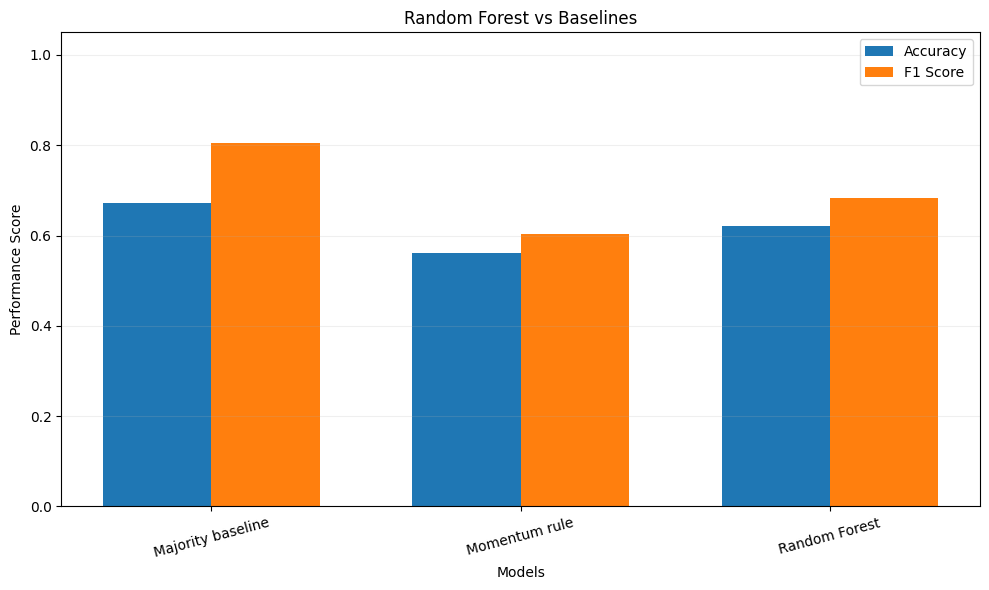

Figure 1 saved.


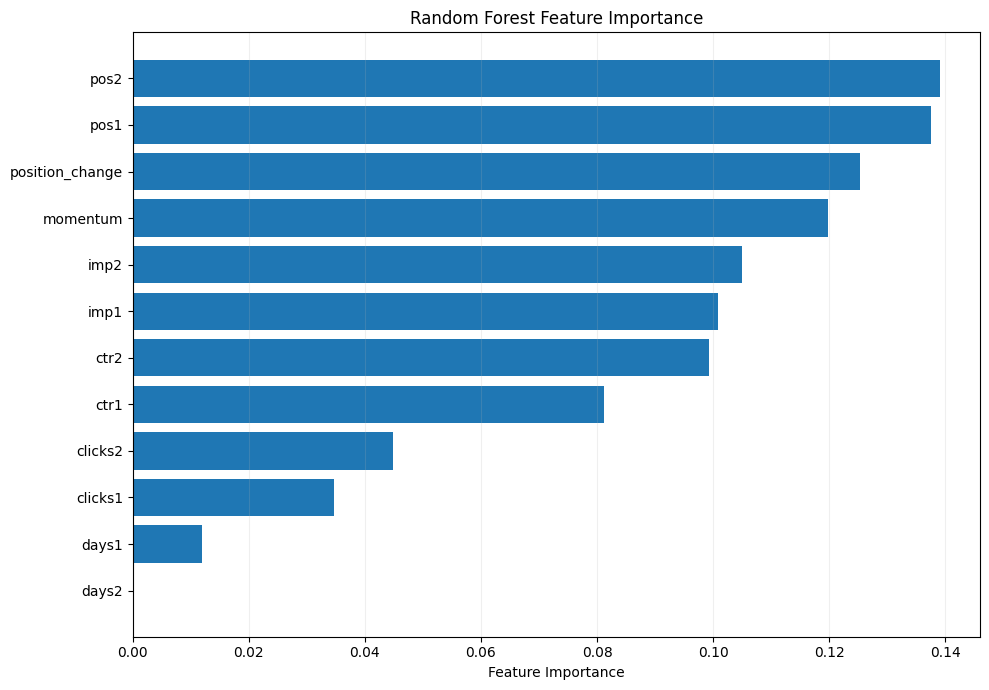

Figure 2 saved.


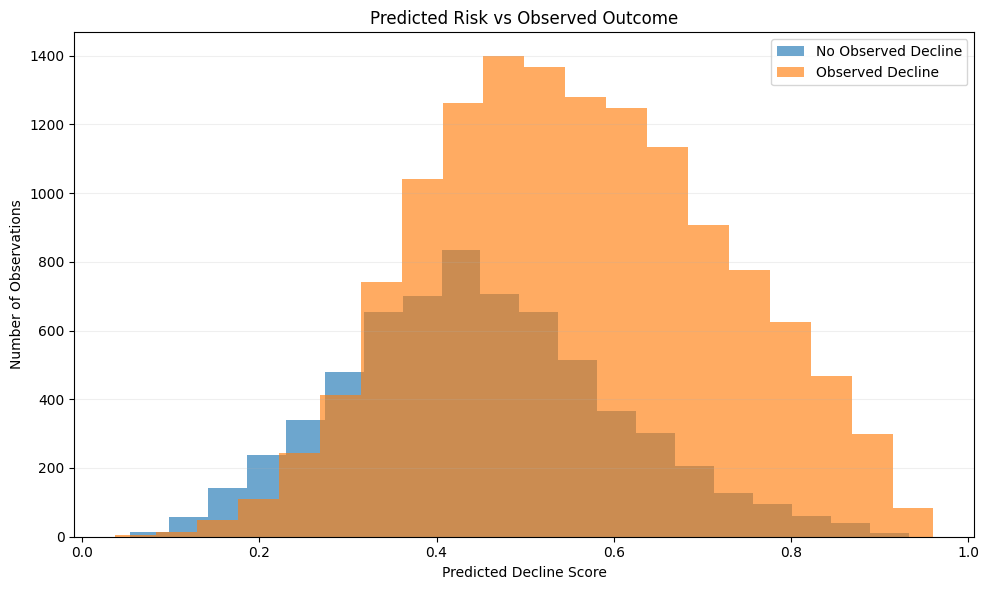

Figure 3 saved.

Research results table:


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Majority baseline,0.673,0.500,0.673,1.000,0.805
1,Momentum rule,0.561,0.597,0.771,0.495,0.603
2,Random Forest,0.622,0.630,0.783,0.605,0.683



Nine-section research paper generated.
ML-12 deliverables generated.



## Capstone Research Artifacts

The following deliverables were generated:

1. Model comparison chart.
2. Feature importance chart.
3. Risk distribution chart.
4. Model evaluation table.
5. Nine-section research paper.
6. ML-12 five-minute demo outline.
7. ML-12 social media post.
8. ML-12 employer-facing summary.

All reported model metrics are calculated from
the previously executed evaluation.


FLYRANK CAPSTONE - FINAL ARTIFACT SUMMARY
- feature_importance.png
- ml12_demo_outline.txt
- ml12_employer_summary.txt
- ml12_social_post.txt
- model_comparison.png
- model_results.csv
- ranked_recommendations.csv
- research_paper.md
- risk_distribution.png
- validation_checks.csv

Research paper: /content/capstone_outputs/research_paper.md
ZIP archive: /content/flyrank_capstone_artifacts.zip

ML-12 DEMO OUTLINE

ML-12 - Five-Minute Research Demo

0:00-0:45 | Research Problem

Explain the importance of identifying content
at risk of search visibility decline.

0:45-1:30 | Dataset

Introduce the FlyRank internship warehouse
and explain the historical observation windows.

1:30-2:30 | Methodology

Explain DuckDB feature engineering,
Random Forest, baselines, and grouped validation.

2:30-3:30 | Model Results

Random Forest accuracy: 62.2%

Majority baseline accuracy: 67.3%

Accuracy difference: -5.1%

ROC-AUC: 0.683

Precision@20: 1.000

3:30-4:15 | Recommendations

Explain the ranked co

In [11]:

# ==========================================
# FLYRANK CAPSTONE - CELL 7
# Research Artifacts + ML-12
# Fixed Matplotlib Compatibility
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil

from pathlib import Path
from IPython.display import display, Markdown

OUTDIR = Path("/content/capstone_outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 1. Check Previous Cells
# ==========================================

required = [
    "results", "model", "feature_cols",
    "rf_score", "y_test", "data",
    "rf_acc", "base_acc", "delta",
    "auc", "ap", "p_at_k",
    "K", "X_train", "X_test"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run previous cells first. Missing: "
        + ", ".join(missing)
    )

SEED = 42

print("Previous results loaded successfully.")

# ==========================================
# 2. Figure 1 - Model Comparison
# ==========================================

model_names = results["Model"].astype(str).tolist()

accuracy_values = results[
    "Accuracy"
].to_numpy(dtype=float)

f1_values = results[
    "F1"
].to_numpy(dtype=float)

positions = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    positions - width / 2,
    accuracy_values,
    width,
    label="Accuracy"
)

ax.bar(
    positions + width / 2,
    f1_values,
    width,
    label="F1 Score"
)

ax.set_title("Random Forest vs Baselines")
ax.set_ylabel("Performance Score")
ax.set_xlabel("Models")

ax.set_xticks(positions)
ax.set_xticklabels(model_names, rotation=15)

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTDIR / "model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure 1 saved.")

# ==========================================
# 3. Figure 2 - Feature Importance
# ==========================================

forest = model.named_steps.get("forest")

if forest is None:
    forest = model.named_steps.get("classifier")

if forest is None:
    raise RuntimeError(
        "Random Forest classifier not found."
    )

importance_values = np.asarray(
    forest.feature_importances_,
    dtype=float
)

feature_names = np.array(feature_cols)

sort_idx = np.argsort(importance_values)

sorted_features = feature_names[sort_idx]
sorted_importance = importance_values[sort_idx]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    np.arange(len(sorted_features)),
    sorted_importance
)

ax.set_yticks(np.arange(len(sorted_features)))
ax.set_yticklabels(sorted_features)

ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Feature Importance")

ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTDIR / "feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure 2 saved.")

# ==========================================
# 4. Figure 3 - Risk Distribution
# ==========================================

actual = y_test.to_numpy()
scores = np.asarray(rf_score, dtype=float)

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    scores[actual == 0],
    bins=20,
    alpha=0.65,
    label="No Observed Decline"
)

ax.hist(
    scores[actual == 1],
    bins=20,
    alpha=0.65,
    label="Observed Decline"
)

ax.set_title("Predicted Risk vs Observed Outcome")
ax.set_xlabel("Predicted Decline Score")
ax.set_ylabel("Number of Observations")
ax.legend()

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTDIR / "risk_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure 3 saved.")

# ==========================================
# 5. Create Results Table
# ==========================================

table_lines = [
    "| Model | Accuracy | Precision | Recall | F1 |",
    "|---|---:|---:|---:|---:|"
]

for _, row in results.iterrows():
    table_lines.append(
        f"| {row['Model']} "
        f"| {row['Accuracy']:.3f} "
        f"| {row['Precision']:.3f} "
        f"| {row['Recall']:.3f} "
        f"| {row['F1']:.3f} |"
    )

results_table = "\n".join(table_lines)

top_features = ", ".join(
    feature_names[
        np.argsort(importance_values)[::-1][:3]
    ].tolist()
)

base_rate = float(y_test.mean())

print("\nResearch results table:")
display(results.round(3))

# ==========================================
# 6. Generate Nine-Section Research Paper
# ==========================================

paper = f"""
# Predicting Organic Search Visibility Decline Using Machine Learning

## 1. Abstract

This research investigates whether historical organic search
performance can identify content at risk of future visibility
decline.

The study uses the pseudonymized FlyRank internship warehouse,
containing approximately 78.8 million daily performance records.

Historical search features were engineered using DuckDB,
and a Random Forest classifier was evaluated on held-out clients.

The model achieved {rf_acc:.1%} accuracy compared with
{base_acc:.1%} for the majority-class baseline.

The research supports content-review prioritization
rather than causal conclusions about search rankings.

## 2. Introduction and Research Question

Content teams manage large numbers of pages with limited
resources for performance investigation.

This study addresses the following question:

Can historical organic search performance signals predict
whether a content item will experience a decline exceeding
20% in impressions during the following 30 days?

The intended decision is a prioritized content-review queue.

## 3. Data

Source: FlyRank Internship Warehouse.

The published warehouse contains approximately
78.8 million daily performance records.

Historical observation windows:

- March 3 to April 1, 2026.
- April 2 to May 1, 2026.

Future outcome window:

- May 2 to May 31, 2026.

Eligible content observations: {len(data):,}.

Eligible pseudonymized clients:
{data['client_hash_id'].nunique()}.

Content items require at least 100 impressions in each
historical window, five reporting days in each historical
window, and five reporting days in the outcome window.

The experiment excludes low-traffic items, records with
insufficient reporting coverage, and potentially overlapping
query-level snapshots.

June 2026 remains outside model development.

Client names, website URLs, raw queries, and authentication
tokens are excluded from public outputs.

## 4. Methodology

The problem is formulated as binary classification.

The target represents a future impression decline
greater than 20%.

Historical features include:

- Search impressions.
- Search clicks.
- Click-through rates.
- Average search positions.
- Historical momentum.
- Position change.
- Reporting-day coverage.

Random Forest is the main classifier.

The two baselines are:

1. Majority-class prediction.
2. Historical momentum rule.

GroupShuffleSplit is used to separate entire clients
between training and testing.

Training observations: {len(X_train):,}.

Testing observations: {len(X_test):,}.

Random seed: {SEED}.

Future outcome measurements and client identifiers
are excluded from model features.

## 5. Results

Observed test decline rate: {base_rate:.1%}.

{results_table}

Random Forest ROC-AUC: {auc:.3f}.

Average precision: {ap:.3f}.

Precision@{K}: {p_at_k:.3f}.

Accuracy difference versus majority baseline:
{delta:+.1%}.

All approaches were evaluated on the same held-out
client observations.

### Figure 1 - Model Comparison

![Model Comparison](model_comparison.png)

### Figure 2 - Feature Importance

![Feature Importance](feature_importance.png)

The three highest-ranked features were:
{top_features}.

Feature importance does not establish causality.

### Figure 3 - Predicted Risk Distribution

![Risk Distribution](risk_distribution.png)

## 6. Limitations

This study uses observational data and cannot establish
that any specific content intervention will improve
organic search performance.

The eligibility criteria exclude low-traffic items
and content with insufficient future reporting coverage.

Complete disappearance from search reporting may
therefore be underrepresented.

The main validation uses one historical cutoff
and a client-grouped holdout.

Repeated temporal backtesting and prospective evaluation
were not performed.

Search demand, seasonality, competition, indexing,
and reporting differences may affect measured outcomes.

Predicted model scores are not independently calibrated.

The research supports human decision-making,
not automatic content modification.

## 7. Ranked Recommendations

The trained model provides a ranking of content items
according to estimated future decline risk.

Priority 1:

Investigate high-risk content with negative
historical impression momentum.

Priority 2:

Review content with deteriorating average search positions.

Priority 3:

Investigate content freshness, topical relevance,
and search intent for other high-risk pages.

The top-{K} observations achieved Precision@{K}
of {p_at_k:.3f}.

The overall held-out decline rate was
{base_rate:.3f}.

These recommendations identify investigation priorities,
not guaranteed methods for increasing traffic.

## 8. Reproducibility

Project repository:

https://github.com/mohamedmorsy-ai/flyrank-ml-internship

Notebook location:

work/notebooks/capstone.ipynb

Environment:

- Google Colab
- Python
- DuckDB
- Pandas
- NumPy
- Scikit-learn
- Matplotlib

Random seed: {SEED}.

Reproduction requires authorized access to the
FlyRank internship warehouse.

Private client data and authentication credentials
are not included in public artifacts.

## 9. Acknowledgments & Data Credit

This research was developed as part of the
FlyRank Machine Learning Internship.

The pseudonymized internship warehouse
was provided by FlyRank for educational analysis.

Official website:

https://flyrank.ai

The findings reflect an independent internship
research exercise and are limited to the
observed data and validation design.
"""

paper_path = OUTDIR / "research_paper.md"

paper_path.write_text(
    paper.strip(),
    encoding="utf-8"
)

print("\nNine-section research paper generated.")

# ==========================================
# 7. ML-12 - Five-Minute Demo
# ==========================================

demo = f"""
ML-12 - Five-Minute Research Demo

0:00-0:45 | Research Problem

Explain the importance of identifying content
at risk of search visibility decline.

0:45-1:30 | Dataset

Introduce the FlyRank internship warehouse
and explain the historical observation windows.

1:30-2:30 | Methodology

Explain DuckDB feature engineering,
Random Forest, baselines, and grouped validation.

2:30-3:30 | Model Results

Random Forest accuracy: {rf_acc:.1%}

Majority baseline accuracy: {base_acc:.1%}

Accuracy difference: {delta:+.1%}

ROC-AUC: {auc:.3f}

Precision@{K}: {p_at_k:.3f}

3:30-4:15 | Recommendations

Explain the ranked content-review queue.

Show the model comparison and feature importance charts.

4:15-5:00 | Limitations and Conclusion

Discuss selection bias, reporting limitations,
uncertainty, and future validation requirements.
"""

# ==========================================
# 8. ML-12 - Social Post
# ==========================================

social = f"""
I completed a machine learning research project
using the FlyRank Internship Warehouse.

The project investigates whether historical search
performance can predict future visibility decline.

I used DuckDB for feature engineering and trained
a Random Forest classifier with client-grouped validation.

The model achieved {rf_acc:.1%} accuracy compared
with {base_acc:.1%} for the majority-class baseline.

I also developed a privacy-safe ranked content-review
workflow and documented the study limitations.

Repository:
https://github.com/mohamedmorsy-ai/flyrank-ml-internship

#MachineLearning #DataScience #Python #DuckDB
"""

# ==========================================
# 9. ML-12 - Employer Summary
# ==========================================

employer = (
    "I developed a reproducible machine learning "
    "workflow using the FlyRank internship warehouse "
    "of approximately 78.8 million daily search records. "
    "I engineered historical features with DuckDB and "
    "evaluated a Random Forest classifier on held-out "
    f"clients, achieving {rf_acc:.1%} accuracy against "
    f"a {base_acc:.1%} majority-class baseline. "
    "The project produced a privacy-safe ranked "
    "content-review workflow with documented "
    "validation assumptions and limitations."
)

# ==========================================
# 10. Save ML-12 Files
# ==========================================

deliverables = {
    "ml12_demo_outline.txt": demo,
    "ml12_social_post.txt": social,
    "ml12_employer_summary.txt": employer
}

for filename, content in deliverables.items():
    (OUTDIR / filename).write_text(
        content.strip(),
        encoding="utf-8"
    )

print("ML-12 deliverables generated.")

# ==========================================
# 11. Package All Public Artifacts
# ==========================================

archive_path = shutil.make_archive(
    "/content/flyrank_capstone_artifacts",
    "zip",
    root_dir=OUTDIR
)

# ==========================================
# 12. Final Summary
# ==========================================

display(Markdown("""
## Capstone Research Artifacts

The following deliverables were generated:

1. Model comparison chart.
2. Feature importance chart.
3. Risk distribution chart.
4. Model evaluation table.
5. Nine-section research paper.
6. ML-12 five-minute demo outline.
7. ML-12 social media post.
8. ML-12 employer-facing summary.

All reported model metrics are calculated from
the previously executed evaluation.
"""))

print("=" * 55)
print("FLYRANK CAPSTONE - FINAL ARTIFACT SUMMARY")
print("=" * 55)

for file in sorted(OUTDIR.iterdir()):
    if file.is_file():
        print("-", file.name)

print("\nResearch paper:", paper_path)
print("ZIP archive:", archive_path)

print("\n" + "=" * 55)
print("ML-12 DEMO OUTLINE")
print("=" * 55)
print(demo)

print("\n" + "=" * 55)
print("ML-12 SOCIAL POST")
print("=" * 55)
print(social)

print("\n" + "=" * 55)
print("ML-12 EMPLOYER SUMMARY")
print("=" * 55)
print(employer)

print("\nSection 7 completed successfully.")


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
